# QPINN — training, evaluation, and plotting
End-to-end walkthrough using the new pipeline (`train.py`, `eval.py`, `plotter.py`).

## 0 - Setup

In [1]:
import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

from src.models import MerlinHeatQPINN
from src.pde import HeatEquation          # swap for BurgersPDE / WavePDE as needed
from src.loss import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_training_history, plot_solution_comparison

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Build QPINN model and PDE

In [3]:
# Model
model = MerlinHeatQPINN()
model = model.to(device)

In [4]:
used_pde = HeatEquation(freq=2.5)

## 2 - Train model

In [5]:
history = train(model = model, pde = used_pde, epochs=300)

Parameters — total: 270  trainable: 270

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 5.7623e+00 | PDE: 4.69e-05 | Cons: 6.29e-03 | IC: 5.62e-01 | BC: 1.43e-01 | Time: 0.3s
Epoch    50/300 | Loss: 4.7871e+00 | PDE: 2.15e-03 | Cons: 3.77e-04 | IC: 4.75e-01 | BC: 3.58e-02 | Time: 7.5s
Epoch   100/300 | Loss: 4.4686e+00 | PDE: 5.66e-02 | Cons: 4.27e-01 | IC: 4.34e-01 | BC: 3.25e-02 | Time: 13.7s
Epoch   150/300 | Loss: 2.4688e+00 | PDE: 3.42e-01 | Cons: 5.79e+00 | IC: 1.43e-01 | BC: 1.18e-01 | Time: 20.2s
Epoch   200/300 | Loss: 1.6553e+00 | PDE: 2.08e-01 | Cons: 5.78e+00 | IC: 8.13e-02 | BC: 5.59e-02 | Time: 26.6s
Epoch   250/300 | Loss: 1.5199e+00 | PDE: 3.08e-01 | Cons: 8.19e+00 | IC: 3.21e-02 | BC: 7.13e-02 | Time: 33.0s
Epoch   300/300 | Loss: 1.2898e+00 | PDE: 2.47e-01 | Cons: 5.19e+00 | IC: 4.86e-02 | BC: 3.77e-02 | Time: 39.5s

Done — 39.5s total


## 3 - Plot training history

Saved: figures/demo/history.png


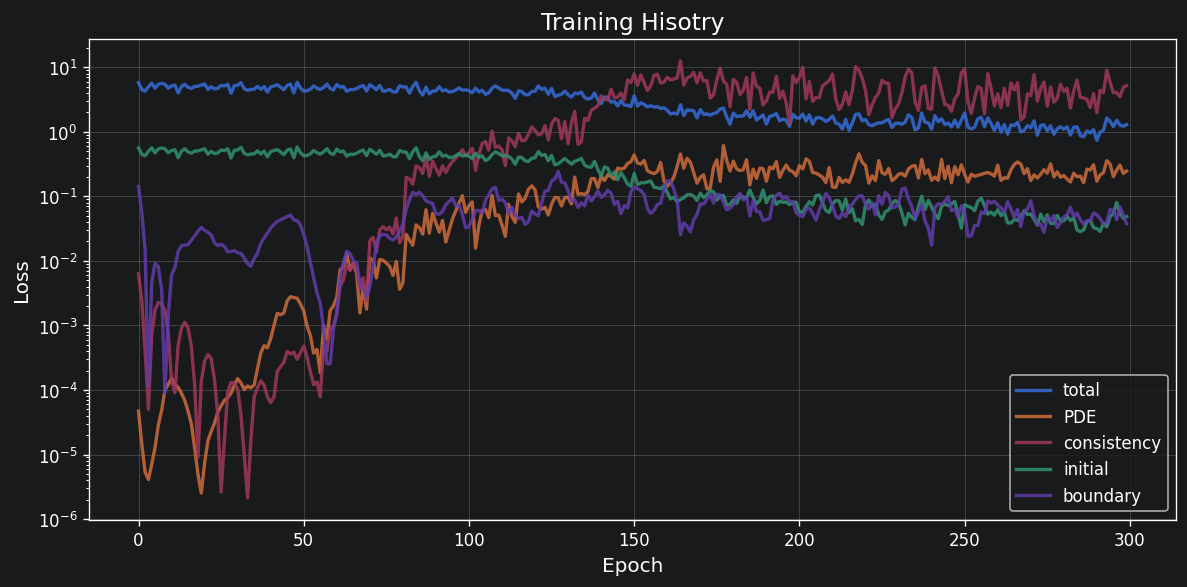

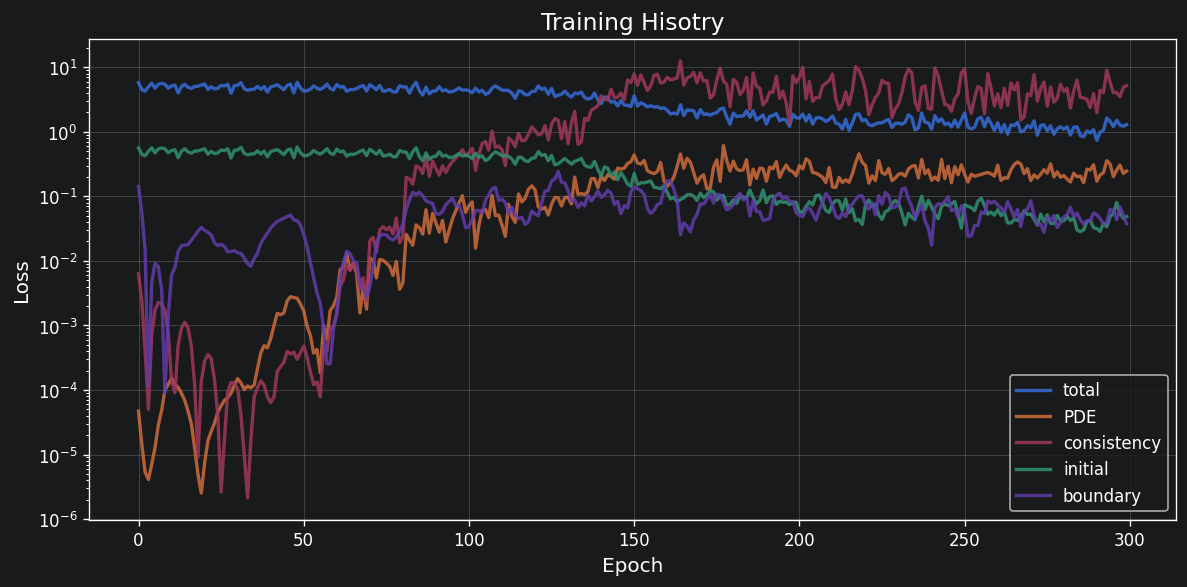

In [7]:
plot_training_history(
    history,
    save_path ='../figures/demo/history.png',  # set to None to skip saving
    show      = True,
)

## 7 - Evaluate model over grid

In [8]:
metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = model,
    pde    = used_pde
)
print(metrics)

Evaluating on 60×60 grid …
  Relative L2 : 7.1653e-01
  MAE         : 1.1576e-01
  Max abs err : 4.1504e-01
  RMSE        : 1.4932e-01
{'rel_l2': 0.7165289521217346, 'mae': 0.11576401442289352, 'max_abs_error': 0.415039598941803, 'rmse': 0.14932115375995636}


## 8 - Plot solution comparison

Saved: figures/demo/solution_quant.png


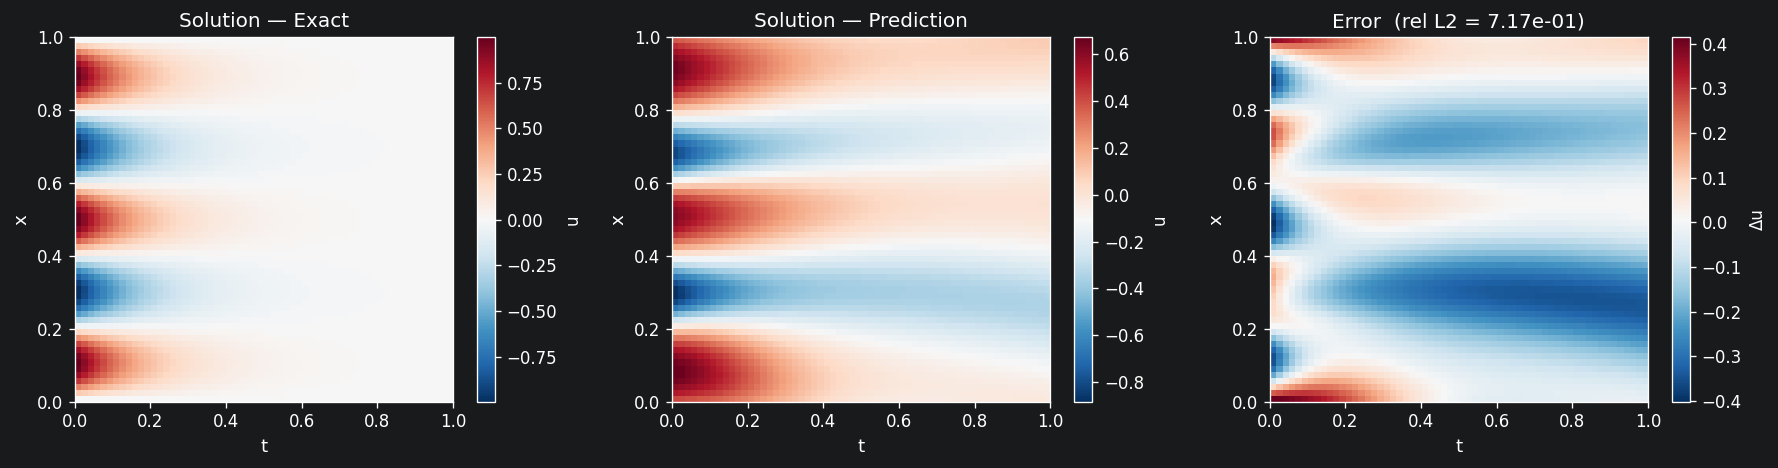

Relative L2 error: 7.1653e-01


In [9]:
fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path ='../figures/demo/solution_quant.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')

## 9 - Repeat process for Classial PINN to compare result

Parameters — total: 250  trainable: 250

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 5.4014e+00 | PDE: 4.95e-05 | Cons: 3.65e-03 | IC: 5.32e-01 | BC: 7.92e-02 | Time: 0.0s
Epoch    50/300 | Loss: 4.8756e+00 | PDE: 5.96e-03 | Cons: 1.49e-03 | IC: 4.84e-01 | BC: 3.30e-02 | Time: 0.3s
Epoch   100/300 | Loss: 4.6671e+00 | PDE: 2.81e-03 | Cons: 3.00e-04 | IC: 4.65e-01 | BC: 1.27e-02 | Time: 0.5s
Epoch   150/300 | Loss: 4.4073e+00 | PDE: 1.87e-03 | Cons: 4.90e-04 | IC: 4.39e-01 | BC: 1.37e-02 | Time: 0.8s
Epoch   200/300 | Loss: 5.4602e+00 | PDE: 3.88e-03 | Cons: 2.60e-04 | IC: 5.46e-01 | BC: 8.67e-04 | Time: 1.1s
Epoch   250/300 | Loss: 4.8149e+00 | PDE: 1.21e-02 | Cons: 1.21e-03 | IC: 4.79e-01 | BC: 8.74e-03 | Time: 1.5s
Epoch   300/300 | Loss: 6.3069e+00 | PDE: 1.19e-02 | Cons: 5.07e-02 | IC: 6.22e-01 | BC: 6.87e-02 | Time: 1.8s

Done — 1.8s total
Evaluating on 60×60 grid …
  Relative L2 : 1.0457e+00
  MAE         : 1.4675e-01
  Max abs err : 1.1438e+00
 

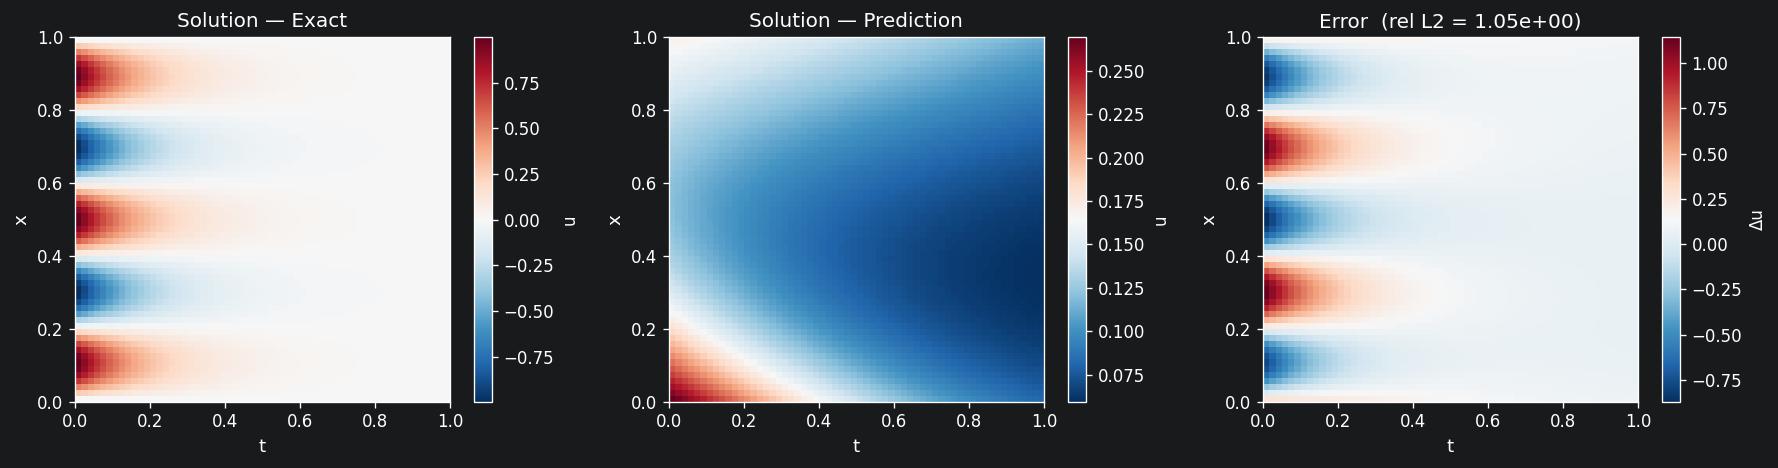

Relative L2 error: 1.0457e+00


In [10]:
from src.models import ClassicalHeatQPINN


classical_model = ClassicalHeatQPINN()
classical_model = classical_model.to(device)


history = train(model = classical_model, pde = used_pde, loss_fn=total_loss, epochs=300)

metrics, U_pred, U_true, x_grid, t_grid = evaluate(
    model  = classical_model,
    pde    = used_pde,
)

fig, rel_l2 = plot_solution_comparison(
    U_pred    = U_pred,
    U_true    = U_true,
    x_grid    = x_grid,
    t_grid    = t_grid,
    save_path ='../figures/demo/solution_class.png',
    show      = True,
)
print(f'Relative L2 error: {rel_l2:.4e}')